## 1. Cấu hình

In [23]:
import gc
import json
import shutil
import time
import traceback
from http.client import HTTPException
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from IPython.display import Image, display
from mne_icalabel import label_components

mne.set_log_level("ERROR")
print("MNE", mne.__version__)

DATA_DIR = Path("data/raw")
OUT_DIR = Path("derivatives/v1")

SUBJECTS = [f"sub-{i:02d}" for i in range(1, 43)]

# Files store channels in different orders (sub-13, sub-41, sub-42 differ), so every
# subject is reordered to this list. Otherwise arrays from different people misalign.
CHANNELS = (
    "Fp1 Fz F3 F7 FT9 FC5 FC1 C3 T7 TP9 CP5 CP1 Pz P3 P7 O1 Oz O2 P4 P8 TP10 CP6 CP2 Cz C4 T8 "
    "FT10 FC6 FC2 F4 F8 Fp2 AF7 AF3 AFz F1 F5 FT7 FC3 C1 C5 TP7 CP3 P1 P5 PO7 PO3 POz PO4 PO8 "
    "P6 P2 CPz CP4 TP8 C6 C2 FC4 FT8 F6 AF8 AF4 F2 F9 AFF1h FFC1h FFC5h FTT7h FCC3h CCP1h "
    "CCP5h TPP7h P9 PPO9h PO9 O9 OI1h PPO1h CPP3h CPP4h PPO2h OI2h O10 PO10 PPO10h P10 TPP8h "
    "CCP6h CCP2h FCC4h FTT8h FFC6h FFC2h AFF2h F10 AFp1 AFF5h FFT9h FFT7h FFC3h FCC1h FCC5h "
    "FTT9h TTP7h CCP3h CPP1h CPP5h TPP9h POO9h PPO5h POO1 POO2 PPO6h POO10h TPP10h CPP6h "
    "CPP2h CCP4h TTP8h FTT10h FCC6h FCC2h FFC4h FFT8h FFT10h AFF6h AFp2 FCz"
).split()

BASE_URL = (
    "https://s3.ap-northeast-1.wasabisys.com/gigadb-datasets/live/pub/"
    "10.5524/100001_101000/100990"
)
DOWNLOAD_ATTEMPTS = 5
DOWNLOAD_RETRY_S = 30

EVENT_ID = {"standard": 5, "target": 6, "distractor": 7}
RESPONSE_CODE = 1
MARKERS = {
    "Stimulus/S  1": RESPONSE_CODE,
    "Stimulus/S  5": 5,
    "Stimulus/S  6": 6,
    "Stimulus/S  7": 7,
}

L_FREQ, H_FREQ = 0.5, 40.0        # same band as the dataset paper
TMIN, TMAX = -0.2, 1.0
DECIM = 4                         # 1000 Hz -> 250 Hz, safe after the 40 Hz low-pass
REJECT = {"eeg": 150e-6}          # peak-to-peak, same for every condition

BAD_Z = 4.0                       # robust z-score of log channel IQR
BAD_NEIGHBOUR_CORR = 0.4          # median correlation with the 6 nearest channels
MIRROR_CORR = -0.8                # anti-correlated neighbours indicate poor contact

ICA_COMPONENTS = 40
ICA_SFREQ = 250
ICLABEL_THRESHOLD = 0.8
# Same classes as the paper (eye, cardiac, muscle). "line noise" is gone after the 40 Hz
# low-pass and bad channels are interpolated, while such components can carry P3 (sub-30).
ICLABEL_ARTIFACTS = {"eye blink", "heart beat", "muscle artifact"}
# Blink components that ICLabel scored below the threshold (0.78 / 0.70 / 0.59), checked by hand:
# removing them brings Fp1 in the epochs from 215 / 171 / 131 uV down to 22 / 69 / 31 uV.
# The indices are valid only for this ICA (RANDOM_STATE, ICA_COMPONENTS, pipeline unchanged).
EXTRA_IC_EXCLUDE = {"sub-13": [0], "sub-14": [0], "sub-36": [2]}
RANDOM_STATE = 97

RT_MIN_MS, RT_MAX_MS = 100, 1400  # paper: <100 ms is anticipation, >stimulus + shortest ISI is late
TASK_MARGIN_S = 5                 # data kept before the first and after the last epoch
SKIP_ANNOTATIONS = ("edge", "bad_acq_skip", "BAD_boundary")

# Facts about specific recordings, from the dataset paper.
EXPECTED_STIMULI = 660
TASK_MISUNDERSTOOD = {"sub-02", "sub-14", "sub-17"}   # 77-99% false alarms to distractors
PAPER_LISTED_IRREGULAR = {"sub-13", "sub-23", "sub-24", "sub-37", "sub-38"}
HIGH_IMPEDANCE = {"sub-23", "sub-24", "sub-32"}       # Table 4: about 8-15 kOhm, typical is 5
P3_WINDOW = (0.3, 0.6)                                # paper: P3 peaks between 300 and 600 ms

for sub_dir in ("epochs", "ica", "qc", "figures"):
    (OUT_DIR / sub_dir).mkdir(parents=True, exist_ok=True)

MNE 1.13.2


## 2. Các hàm xử lý

In [24]:
def download_file(url, dest):
    """Download to dest. After a dropped connection, continue from the .part file."""
    part = dest.with_name(dest.name + ".part")
    headers = {"User-Agent": "Mozilla/5.0"}
    for attempt in range(1, DOWNLOAD_ATTEMPTS + 1):
        try:
            with urlopen(Request(url, headers=headers, method="HEAD"), timeout=120) as response:
                size = int(response.headers["Content-Length"])
            if dest.exists() and dest.stat().st_size == size:
                return
            have = part.stat().st_size if part.exists() else 0
            if have > size:
                part.unlink()
                have = 0
            if have < size:
                request = Request(url, headers={**headers, "Range": f"bytes={have}-"})
                with urlopen(request, timeout=120) as response:
                    # 206 sends only the missing bytes, a plain 200 sends the whole file.
                    with open(part, "ab" if response.status == 206 else "wb") as f:
                        shutil.copyfileobj(response, f, 1024 * 1024)
            if part.stat().st_size == size:
                part.replace(dest)
                return
            problem = f"got {part.stat().st_size} of {size} bytes"
        except (OSError, HTTPException) as error:
            problem = repr(error)
        print(f"    {dest.name}: attempt {attempt}/{DOWNLOAD_ATTEMPTS} failed ({problem})", flush=True)
        time.sleep(DOWNLOAD_RETRY_S)
    raise IOError(f"Incomplete download: {dest.name}")


def download_subject(sub):
    folder = DATA_DIR / sub
    folder.mkdir(parents=True, exist_ok=True)
    for ext in ("vhdr", "vmrk", "eeg"):
        name = f"{sub}_task-oddball_eeg.{ext}"
        download_file(f"{BASE_URL}/{sub}/eeg/{name}", folder / name)
    return folder / f"{sub}_task-oddball_eeg.vhdr"


def make_montage():
    montage = mne.channels.make_standard_montage("colin27_1005")
    montage.rename_channels({"I1": "O9", "I2": "O10"})
    return montage


def load_raw(vhdr):
    raw = mne.io.read_raw_brainvision(vhdr, preload=True)
    raw.rename_channels({"TP9 LEFT EAR": "TP9", "TP10 RIGHT EAR": "TP10"})
    mne.add_reference_channels(raw, "FCz", copy=False)
    raw.reorder_channels(CHANNELS)
    raw.set_montage(make_montage())
    return raw


def crop_to_task(raw):
    """Keep only the task. Some recordings continue after the last stimulus with artifacts of
    up to 3000 uV (cap removal, movement), which wreck the bad-channel check and ICA."""
    events, _ = mne.events_from_annotations(raw, event_id=MARKERS)
    stim_s = (events[np.isin(events[:, 2], list(EVENT_ID.values())), 0] - raw.first_samp) / raw.info["sfreq"]
    before = raw.times[-1]
    raw.crop(
        tmin=max(0.0, stim_s.min() - TASK_MARGIN_S),
        tmax=min(raw.times[-1], stim_s.max() + TMAX + TASK_MARGIN_S),
    )
    return before - raw.times[-1]


def mark_boundaries(raw):
    """Annotate internal recording joins so filters and epochs do not cross them."""
    is_join = np.array([
        d in ("New Segment/", "Stimulus/boundary") and o > 0
        for d, o in zip(raw.annotations.description, raw.annotations.onset)
    ])
    onsets = sorted(set(raw.annotations.onset[is_join].round(3)))
    if onsets:
        raw.annotations.append(onsets, 0.002, "BAD_boundary")
    return len(onsets)


def find_bad_channels(raw):
    """Flag noisy or flat, poorly correlated and mirrored channels on a median-referenced copy."""
    tmp = raw.copy().resample(200).filter(1, 40, skip_by_annotation=SKIP_ANNOTATIONS)
    data = tmp.get_data()
    data -= np.median(data, axis=0)
    names = np.array(tmp.ch_names)

    # IQR ignores brief blinks, which would otherwise flag Fp1/Fp2 before ICA can remove them.
    log_spread = np.log(np.subtract(*np.percentile(data, [75, 25], axis=1)) + 1e-12)
    centre = np.median(log_spread)
    z = (log_spread - centre) / (1.4826 * np.median(np.abs(log_spread - centre)))

    corr = np.corrcoef(data)
    pos = np.array([ch["loc"][:3] for ch in tmp.info["chs"]])
    dist = np.linalg.norm(pos[:, None] - pos[None], axis=-1)
    neighbours = np.argsort(dist, axis=1)[:, 1:7]
    neighbour_corr = np.take_along_axis(corr, neighbours, axis=1)

    reasons = {
        "noisy_or_flat": names[np.abs(z) > BAD_Z].tolist(),
        "uncorrelated": names[np.median(neighbour_corr, axis=1) < BAD_NEIGHBOUR_CORR].tolist(),
        "mirrored": names[(neighbour_corr < MIRROR_CORR).any(axis=1)].tolist(),
    }
    return sorted({ch for chs in reasons.values() for ch in chs}), reasons


def run_ica(raw):
    """Fit ICA on a 1-100 Hz average-referenced copy, as ICLabel expects."""
    ica_raw = (
        raw.copy()
        .filter(1, 100, skip_by_annotation=SKIP_ANNOTATIONS)
        .resample(ICA_SFREQ)
    )
    ica = mne.preprocessing.ICA(
        n_components=ICA_COMPONENTS,
        method="picard",
        fit_params={"ortho": False, "extended": True},
        max_iter="auto",
        random_state=RANDOM_STATE,
    )
    ica.fit(ica_raw)
    result = label_components(ica_raw, ica, method="iclabel")
    labels = [(l, float(p)) for l, p in zip(result["labels"], result["y_pred_proba"])]
    ica.exclude = [
        i for i, (l, p) in enumerate(labels)
        if l in ICLABEL_ARTIFACTS and p >= ICLABEL_THRESHOLD
    ]
    return ica, labels


def build_metadata(events, sfreq, sub):
    """One row per stimulus, with the behaviour needed to study the button-press confound."""
    code_to_name = {code: name for name, code in EVENT_ID.items()}
    stim = events[np.isin(events[:, 2], list(EVENT_ID.values()))]
    responses = events[events[:, 2] == RESPONSE_CODE, 0]

    rows = []
    for i, (sample, _, code) in enumerate(stim):
        next_sample = stim[i + 1, 0] if i + 1 < len(stim) else np.inf
        rts = (responses[(responses >= sample) & (responses < next_sample)] - sample) * 1000 / sfreq
        in_window = rts.size > 0 and RT_MIN_MS <= rts[0] <= RT_MAX_MS
        is_target = code == EVENT_ID["target"]
        rows.append({
            "subject": sub,
            "trial": i,
            "condition": code_to_name[code],
            "responded": bool(rts.size),
            "rt_ms": float(rts[0]) if rts.size else np.nan,
            "correct": bool(in_window) if is_target else not rts.size,
        })
    return stim, pd.DataFrame(rows)


def behaviour_summary(meta):
    by = {name: meta[meta["condition"] == name] for name in EVENT_ID}
    good = by["target"][by["target"]["correct"]]
    return {
        "target_rt_ms": round(float(good["rt_ms"].mean()), 1),
        "target_omission_pct": round(100 * float((~by["target"]["responded"]).mean()), 2),
        "false_alarm_distractor_pct": round(100 * float(by["distractor"]["responded"].mean()), 2),
        "false_alarm_standard_pct": round(100 * float(by["standard"]["responded"].mean()), 2),
    }


def window_mean_uv(epochs, condition, channel):
    evoked = epochs[condition].average(picks=channel)
    return round(float(evoked.copy().crop(*P3_WINDOW).data.mean() * 1e6), 2)


def save_erp_figure(epochs, sub):
    colours = {"standard": "#4d4d4d", "target": "#d55e00", "distractor": "#0072b2"}
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
    for ax, channel in zip(axes, ("Fz", "Pz")):
        for name, colour in colours.items():
            evoked = epochs[name].average(picks=channel)
            ax.plot(evoked.times * 1000, evoked.data[0] * 1e6, color=colour,
                    label=f"{name} (n={len(epochs[name])})")
        ax.axvline(0, color="k", lw=0.5)
        ax.axhline(0, color="k", lw=0.5)
        ax.set(title=f"{sub} – {channel}", xlabel="Time (ms)")
    axes[0].set_ylabel("Amplitude (µV)")
    axes[0].legend(frameon=False)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "figures" / f"{sub}_erp.png", dpi=150)
    plt.show()
    plt.close(fig)

In [25]:
def preprocess_subject(sub):
    start = time.time()
    raw = load_raw(download_subject(sub))
    cropped_s = crop_to_task(raw)
    n_joins = mark_boundaries(raw)

    events, _ = mne.events_from_annotations(raw, event_id=MARKERS)
    stim, meta = build_metadata(events, raw.info["sfreq"], sub)
    behaviour = behaviour_summary(meta)

    bads, bad_reasons = find_bad_channels(raw)
    raw.info["bads"] = bads
    raw.interpolate_bads(reset_bads=True)
    raw.set_eeg_reference("average", projection=False)

    ica, ic_labels = run_ica(raw)
    ica.exclude = sorted(set(ica.exclude) | set(EXTRA_IC_EXCLUDE.get(sub, [])))

    raw.filter(L_FREQ, H_FREQ, skip_by_annotation=SKIP_ANNOTATIONS)
    fp1_before = np.percentile(np.abs(raw.get_data(picks="Fp1")), 99) * 1e6
    ica.apply(raw)
    fp1_after = np.percentile(np.abs(raw.get_data(picks="Fp1")), 99) * 1e6

    epochs = mne.Epochs(
        raw, stim, event_id=EVENT_ID, tmin=TMIN, tmax=TMAX, baseline=(None, 0),
        metadata=meta, reject=REJECT, reject_by_annotation=True,
        decim=DECIM, preload=True,
    )

    epochs.save(OUT_DIR / "epochs" / f"{sub}_task-oddball_v1-epo.fif", overwrite=True, fmt="single")
    ica.save(OUT_DIR / "ica" / f"{sub}-ica.fif", overwrite=True)
    save_erp_figure(epochs, sub)

    counts_in = meta["condition"].value_counts()
    counts_out = epochs.metadata["condition"].value_counts()
    qc = {
        "subject": sub,
        "task_misunderstood": sub in TASK_MISUNDERSTOOD,
        "irregular_recording": (
            n_joins > 0 or len(meta) != EXPECTED_STIMULI or sub in PAPER_LISTED_IRREGULAR
        ),
        "high_impedance": sub in HIGH_IMPEDANCE,
        "n_recording_joins": n_joins,
        "cropped_outside_task_s": round(float(cropped_s), 1),
        "n_stimuli": len(meta),
        "n_bad_channels": len(bads),
        "bad_channels": bads,
        "bad_channel_reasons": bad_reasons,
        "n_ic_excluded": len(ica.exclude),
        "ic_excluded": [f"{ic_labels[i][0]} ({ic_labels[i][1]:.2f})" for i in ica.exclude],
        "fp1_p99_before_ica_uv": round(float(fp1_before), 1),
        "fp1_p99_after_ica_uv": round(float(fp1_after), 1),
        **behaviour,
        **{f"n_{name}_in": int(counts_in.get(name, 0)) for name in EVENT_ID},
        **{f"n_{name}_kept": int(counts_out.get(name, 0)) for name in EVENT_ID},
        "pct_trials_dropped": round(100 * (1 - len(epochs) / len(meta)), 1),
        **{f"pz_p3_{name}_uv": window_mean_uv(epochs, name, "Pz") for name in EVENT_ID},
        "n_channels": len(epochs.ch_names),
        "n_times": len(epochs.times),
        "runtime_s": round(time.time() - start),
    }
    (OUT_DIR / "qc" / f"{sub}.json").write_text(json.dumps(qc, indent=2), encoding="utf-8")
    del raw, epochs, ica
    gc.collect()
    return qc

## 3. Chạy


In [26]:
def is_done(sub):
    return (
        (OUT_DIR / "qc" / f"{sub}.json").exists()
        and (OUT_DIR / "epochs" / f"{sub}_task-oddball_v1-epo.fif").exists()
    )


def run_batch(subjects):
    """Process a group of subjects. A failure is reported and the next subject continues."""
    for sub in subjects:
        progress = f"[{SUBJECTS.index(sub) + 1}/{len(SUBJECTS)}] {sub}"
        if is_done(sub):
            print(progress, "already processed, skipping", flush=True)
            display(Image(filename=str(OUT_DIR / "figures" / f"{sub}_erp.png"), width=1000))
            continue
        print(progress, "processing...", flush=True)
        try:
            qc = preprocess_subject(sub)
            print(f"    done in {qc['runtime_s']} s | dropped {qc['pct_trials_dropped']} %", flush=True)
        except Exception:
            print("    FAILED")
            print(traceback.format_exc(), flush=True)

[1/42] sub-01 processing...


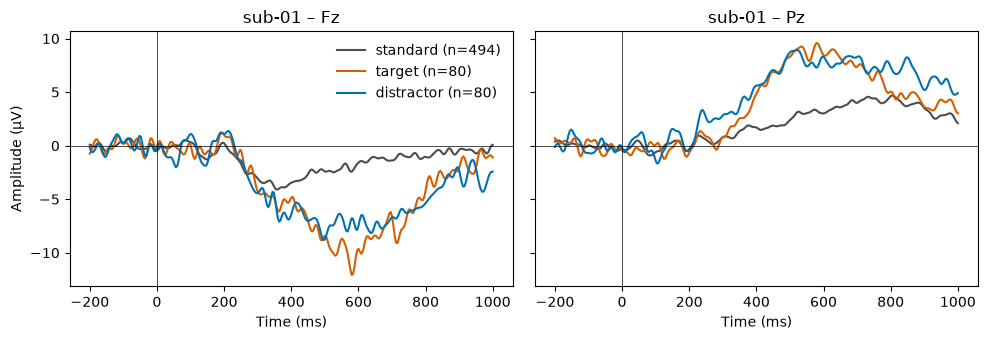

    done in 149 s | dropped 0.9 %
[2/42] sub-02 processing...


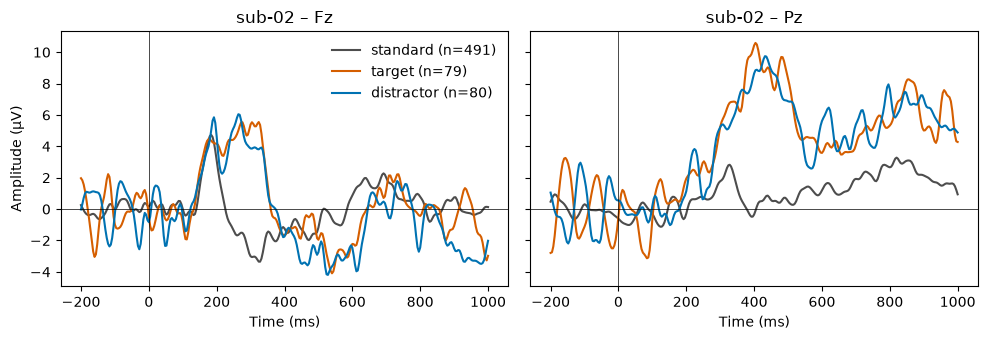

    done in 312 s | dropped 1.5 %
[3/42] sub-03 processing...


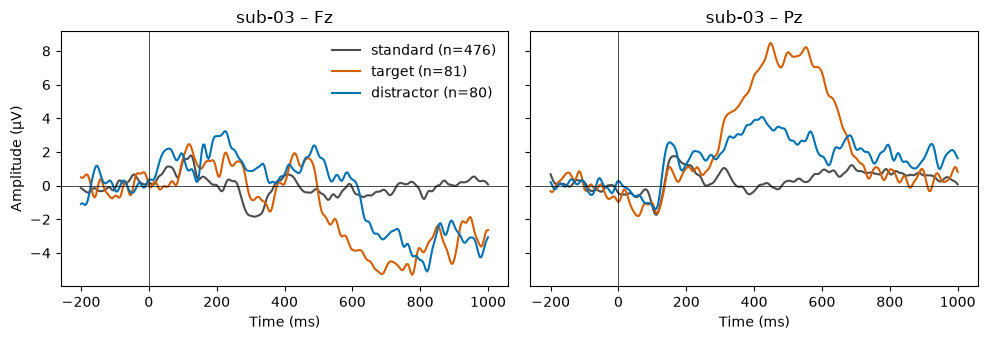

    done in 173 s | dropped 3.5 %
[4/42] sub-04 processing...


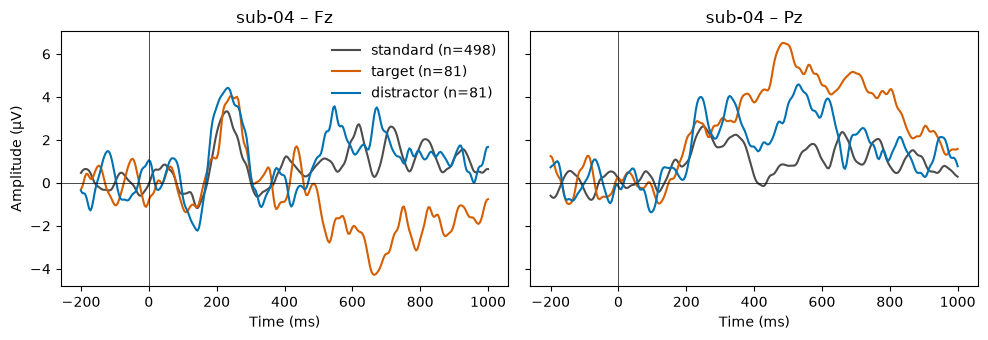

    done in 251 s | dropped 0.0 %
[5/42] sub-05 processing...


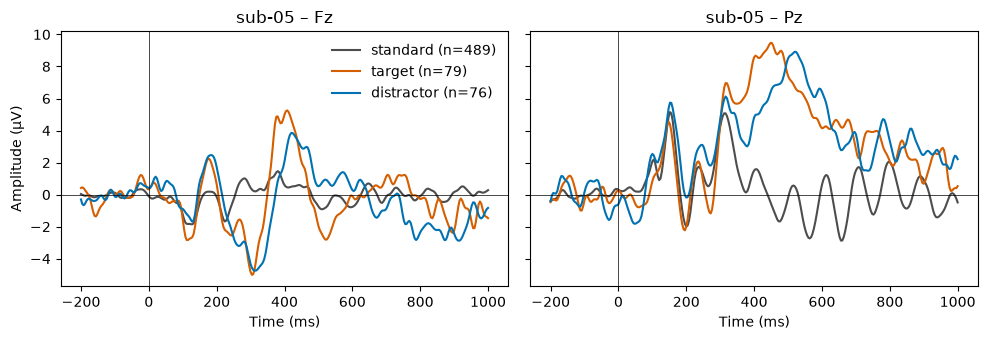

    done in 157 s | dropped 2.4 %


In [27]:
run_batch(SUBJECTS[0:5])  # sub-01 to sub-05

[6/42] sub-06 processing...


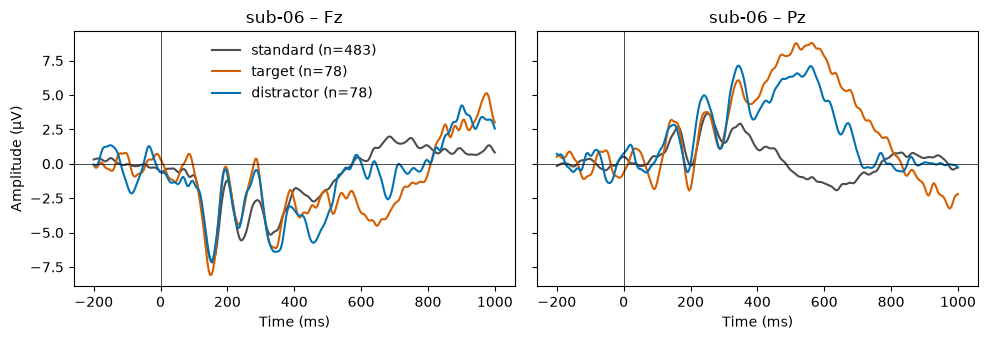

    done in 148 s | dropped 3.2 %
[7/42] sub-07 processing...


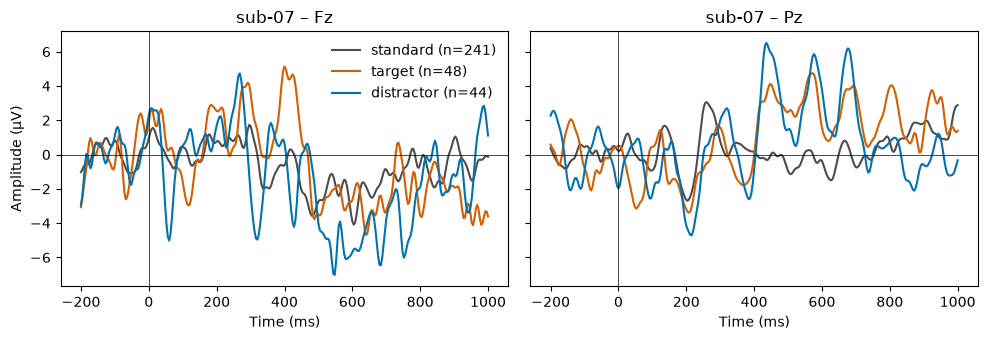

    done in 157 s | dropped 49.5 %
[8/42] sub-08 processing...


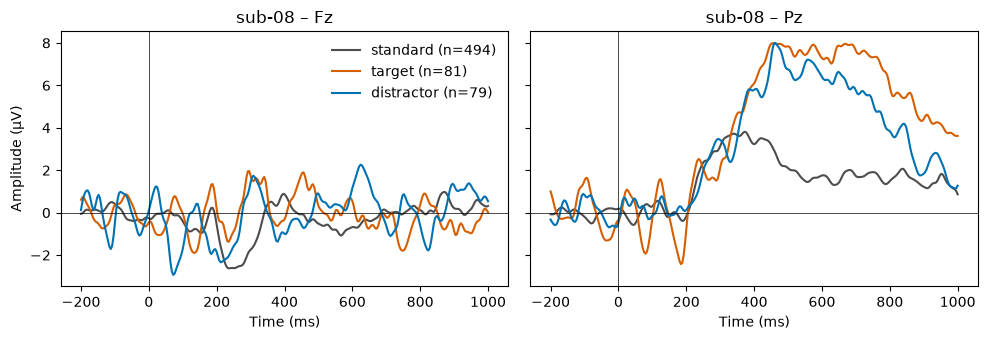

    done in 163 s | dropped 0.9 %
[9/42] sub-09 processing...


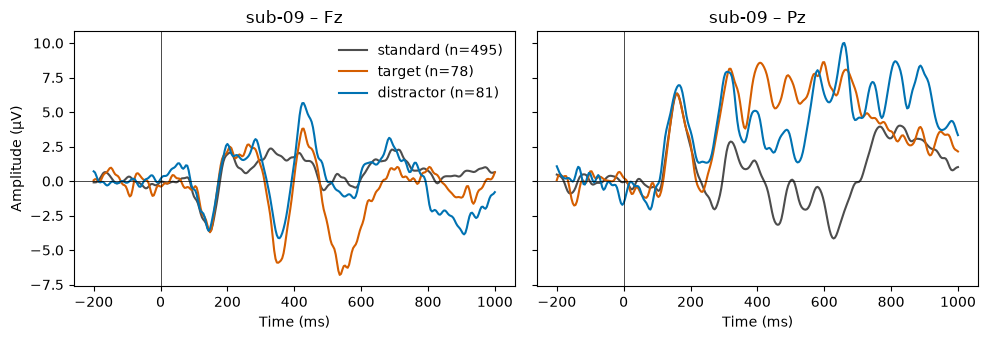

    done in 226 s | dropped 0.9 %
[10/42] sub-10 processing...


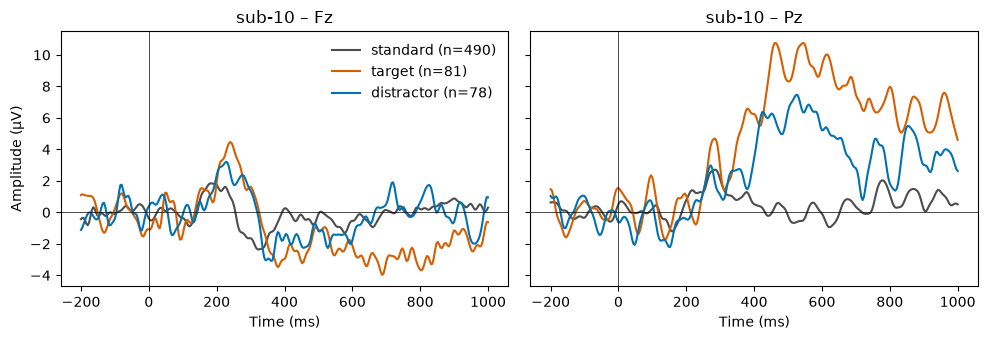

    done in 372 s | dropped 1.7 %


In [28]:
run_batch(SUBJECTS[5:10])  # sub-06 to sub-10

[11/42] sub-11 processing...


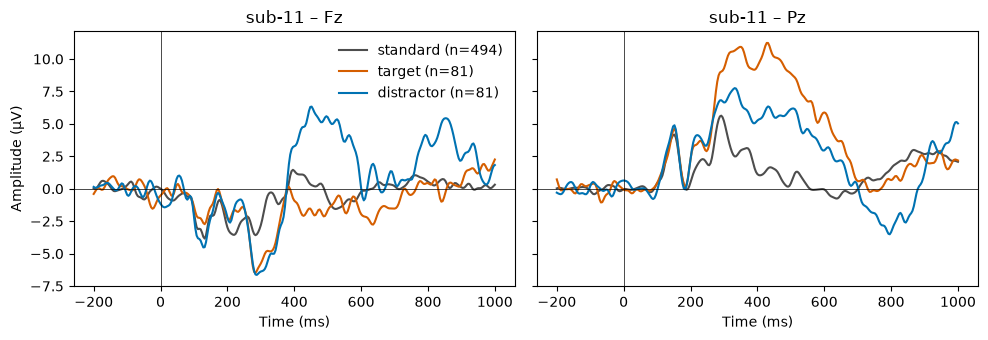

    done in 465 s | dropped 0.6 %
[12/42] sub-12 processing...


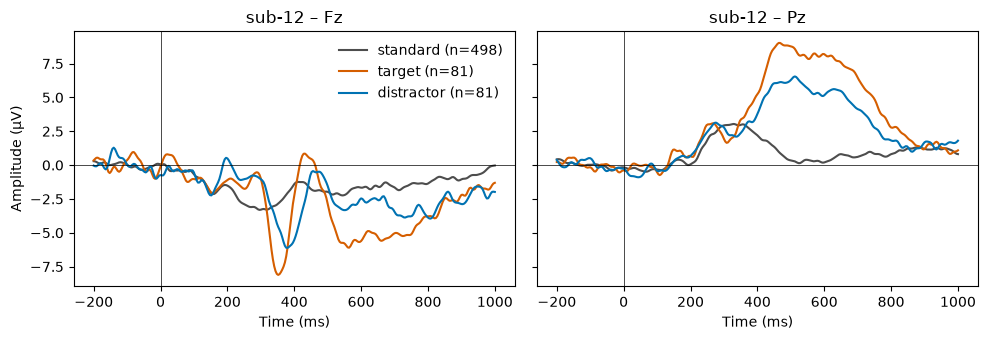

    done in 275 s | dropped 0.0 %
[13/42] sub-13 processing...


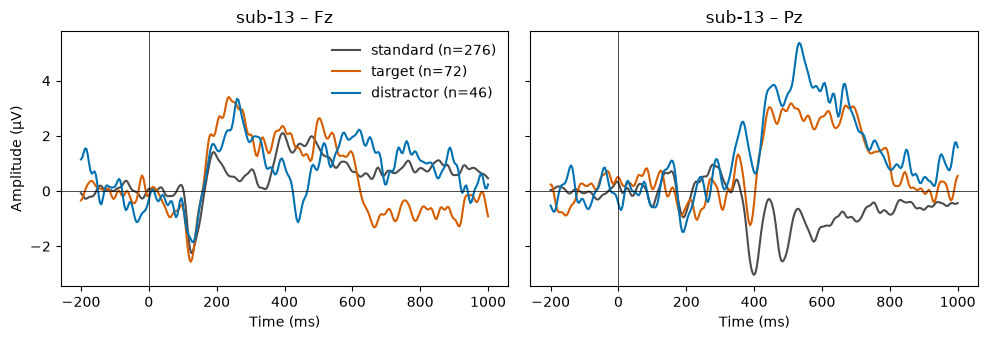

    done in 164 s | dropped 40.3 %
[14/42] sub-14 processing...


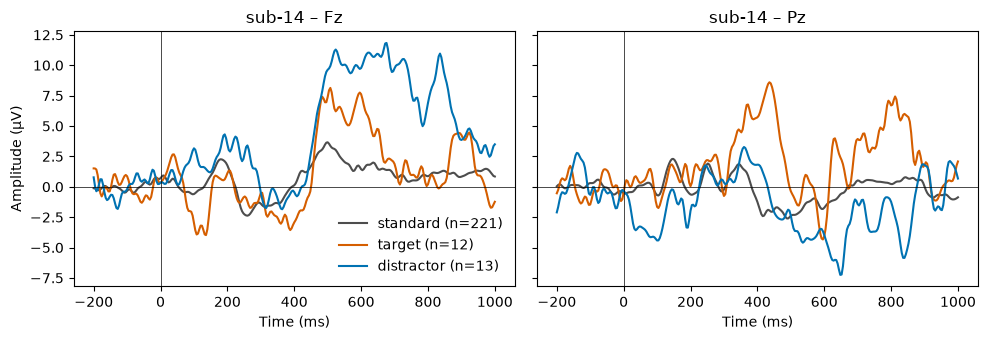

    done in 144 s | dropped 62.7 %
[15/42] sub-15 processing...


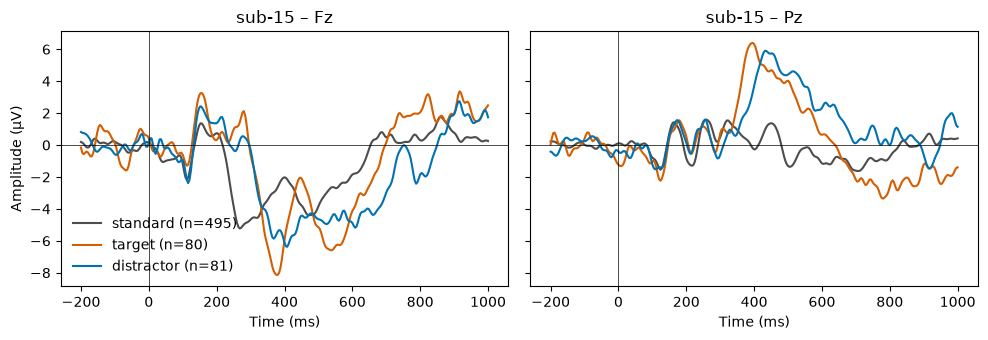

    done in 148 s | dropped 0.6 %


In [29]:
run_batch(SUBJECTS[10:15])  # sub-11 to sub-15

[16/42] sub-16 processing...


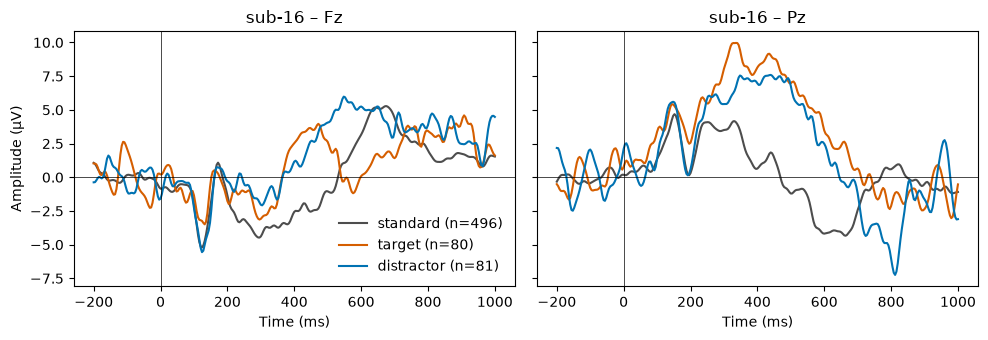

    done in 129 s | dropped 0.5 %
[17/42] sub-17 processing...


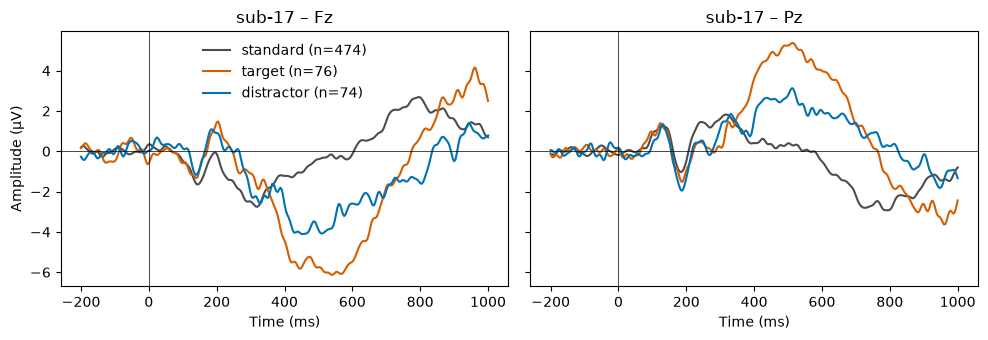

    done in 278 s | dropped 5.5 %
[18/42] sub-18 processing...


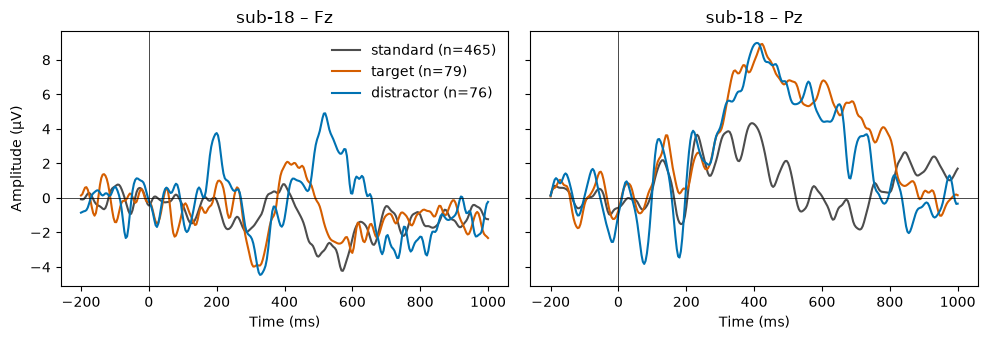

    done in 174 s | dropped 6.1 %
[19/42] sub-19 processing...


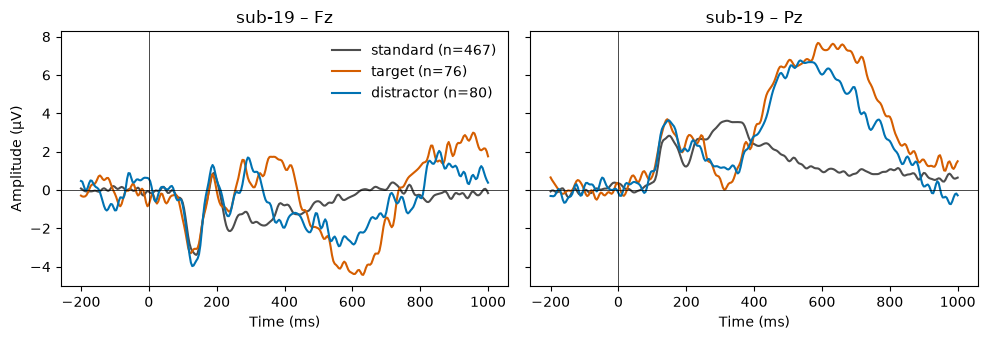

    done in 275 s | dropped 5.6 %
[20/42] sub-20 processing...


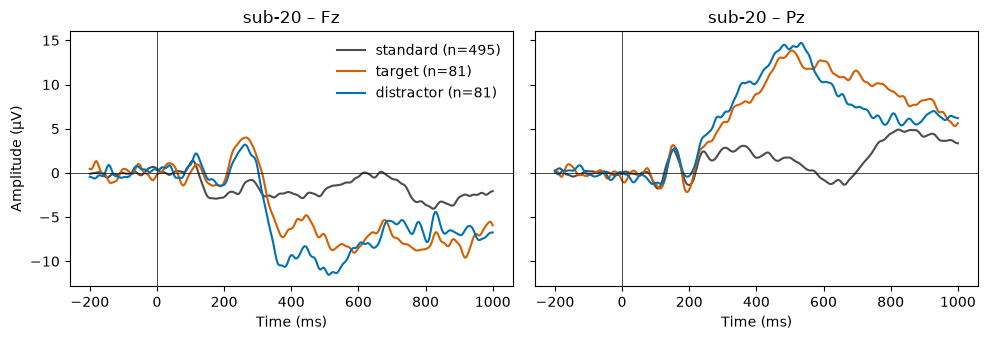

    done in 293 s | dropped 0.5 %


In [30]:
run_batch(SUBJECTS[15:20])  # sub-16 to sub-20

[21/42] sub-21 processing...


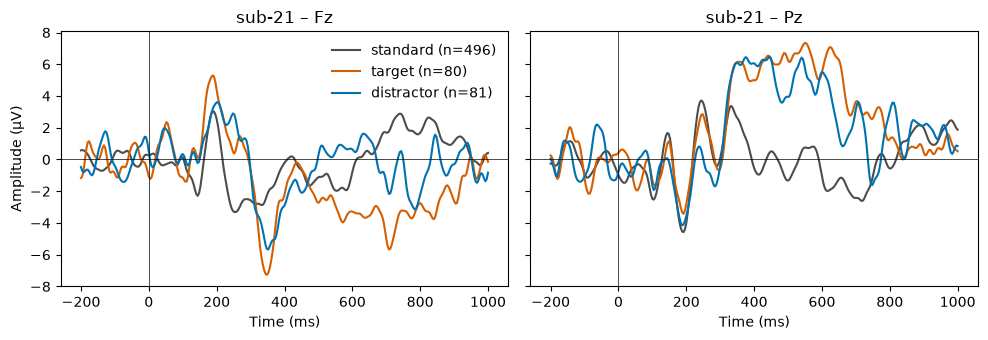

    done in 179 s | dropped 0.5 %
[22/42] sub-22 processing...


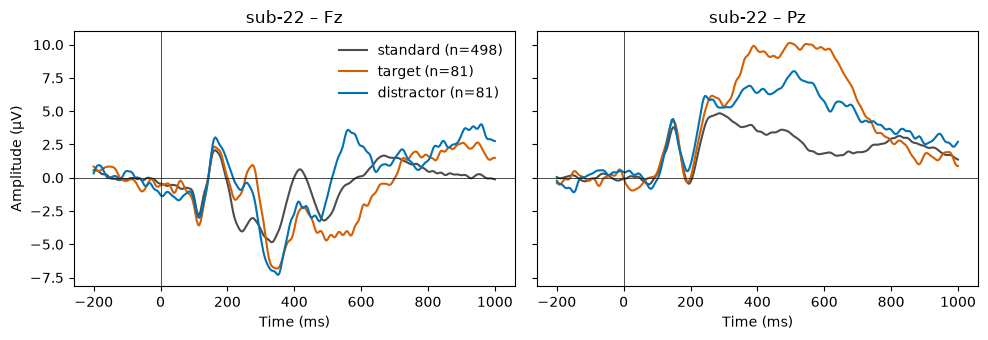

    done in 204 s | dropped 0.0 %
[23/42] sub-23 processing...


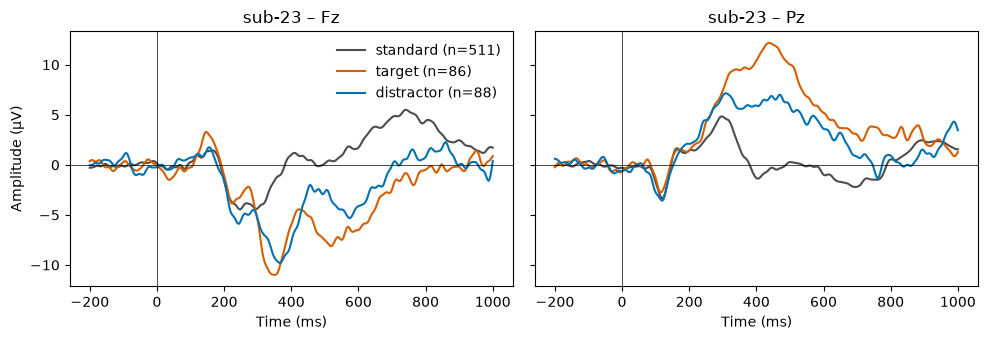

    done in 220 s | dropped 1.0 %
[24/42] sub-24 processing...


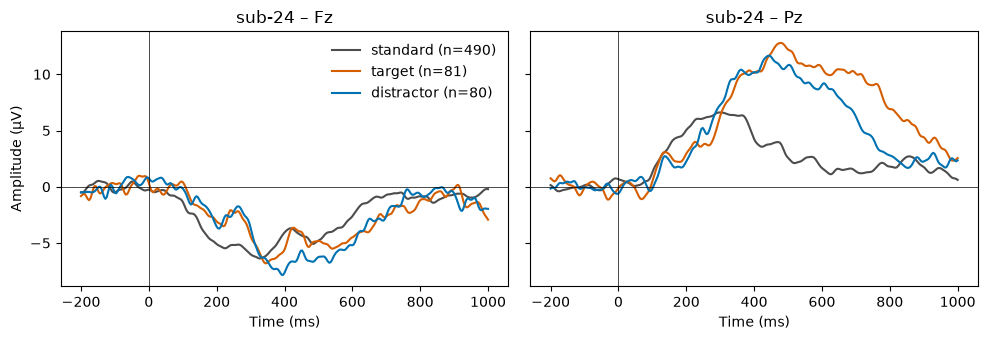

    done in 149 s | dropped 1.2 %
[25/42] sub-25 processing...


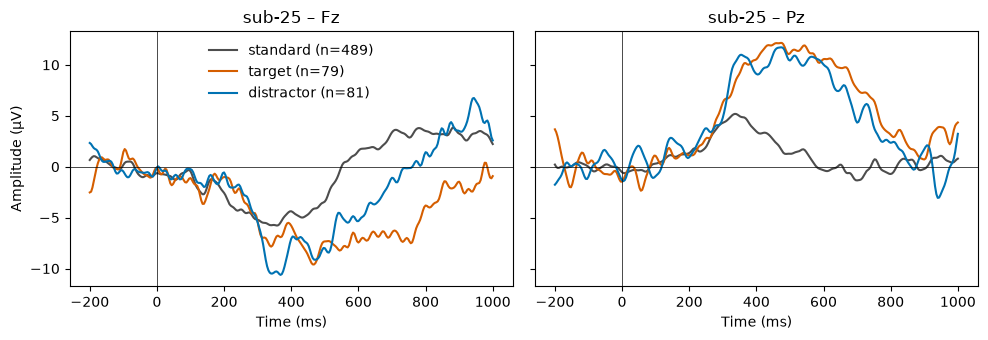

    done in 159 s | dropped 1.7 %


In [31]:
run_batch(SUBJECTS[20:25])  # sub-21 to sub-25

[26/42] sub-26 processing...


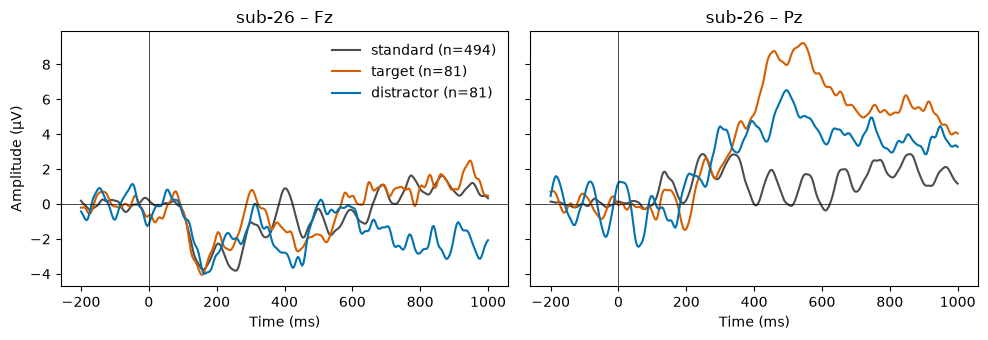

    done in 161 s | dropped 0.6 %
[27/42] sub-27 processing...


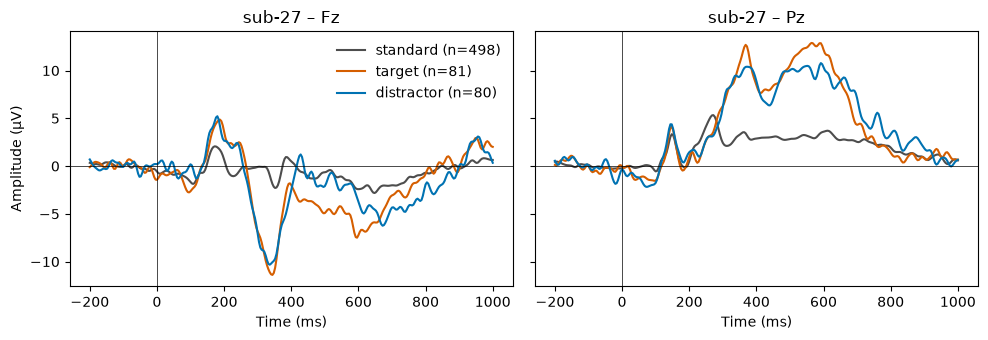

    done in 153 s | dropped 0.2 %
[28/42] sub-28 processing...


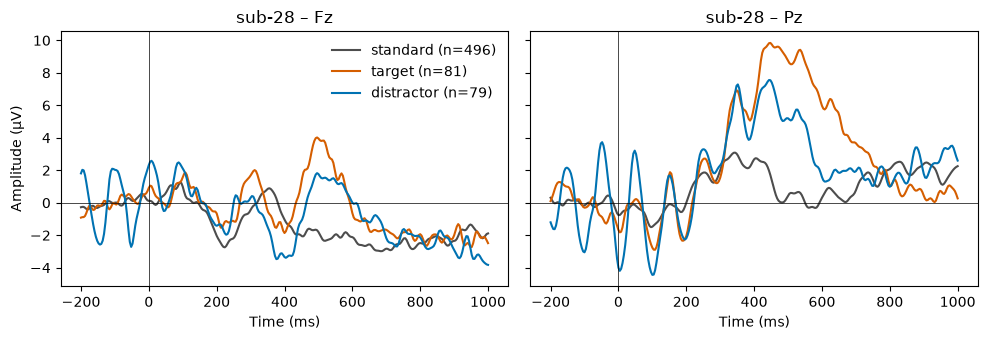

    done in 131 s | dropped 0.6 %
[29/42] sub-29 processing...


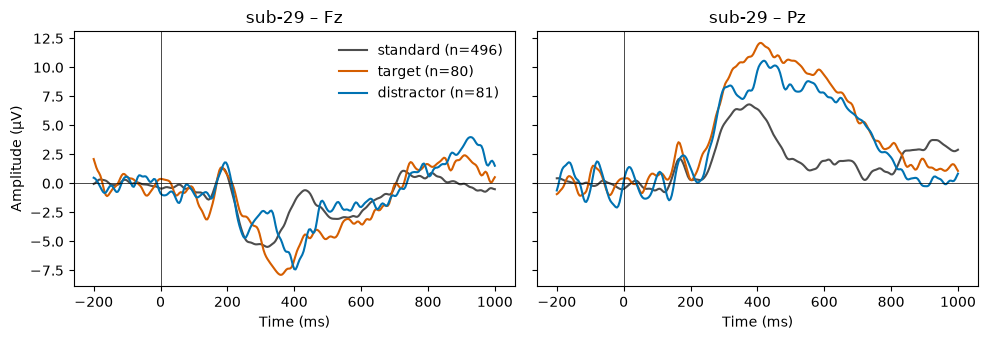

    done in 144 s | dropped 0.5 %
[30/42] sub-30 processing...


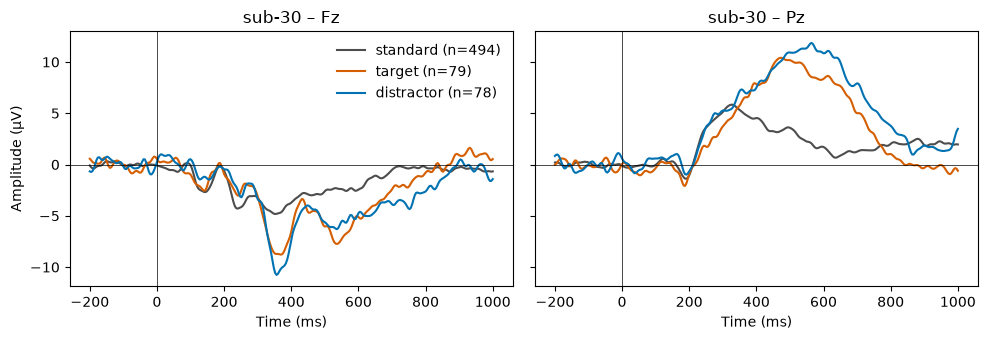

    done in 126 s | dropped 1.4 %


In [32]:
run_batch(SUBJECTS[25:30])  # sub-26 to sub-30

[31/42] sub-31 processing...


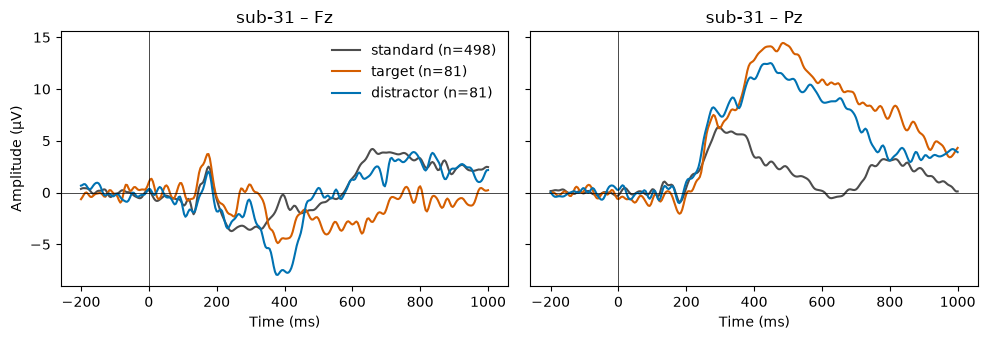

    done in 135 s | dropped 0.0 %
[32/42] sub-32 processing...


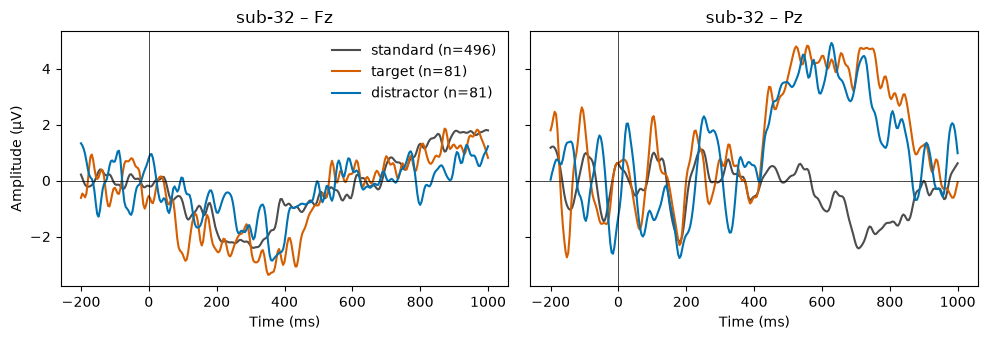

    done in 144 s | dropped 0.3 %
[33/42] sub-33 processing...


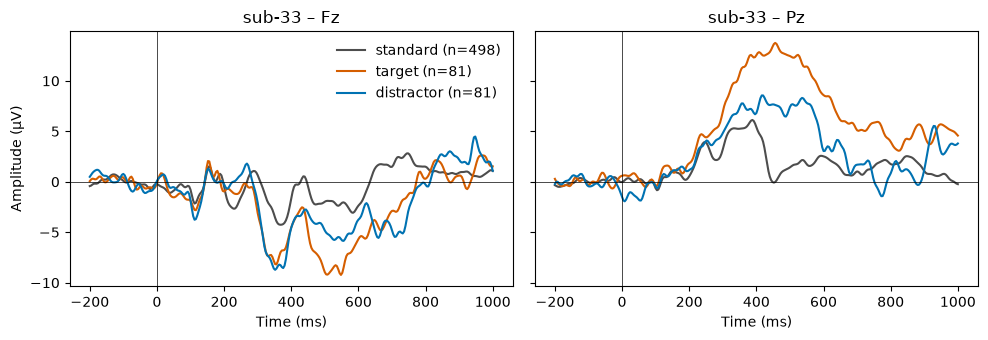

    done in 228 s | dropped 0.0 %
[34/42] sub-34 processing...


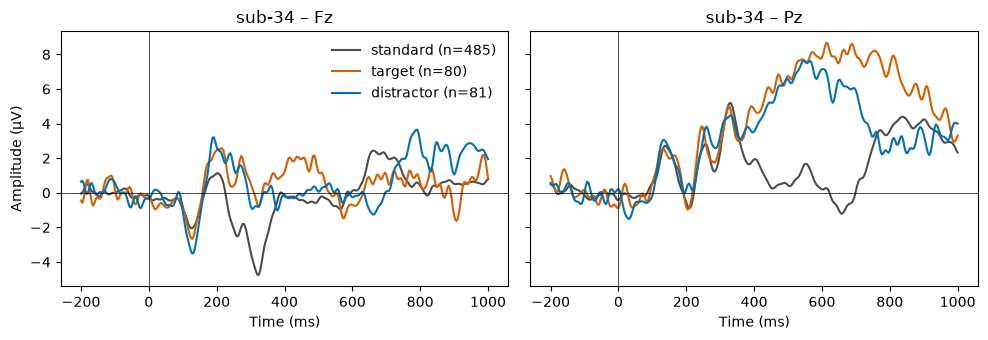

    done in 144 s | dropped 2.1 %
[35/42] sub-35 processing...


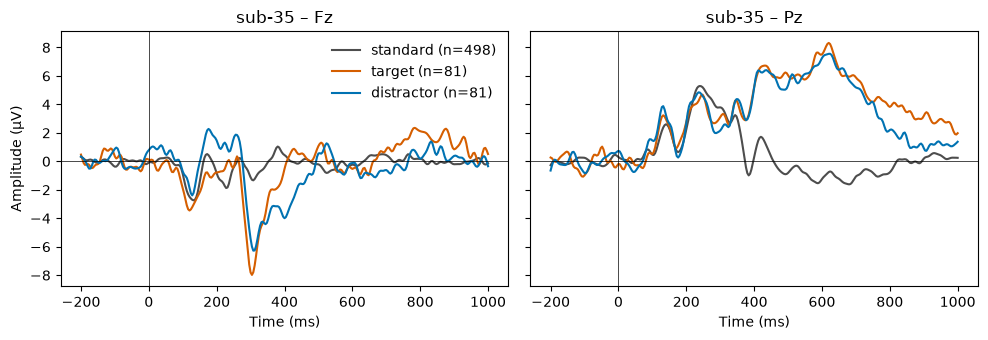

    done in 135 s | dropped 0.0 %


In [33]:
run_batch(SUBJECTS[30:35])  # sub-31 to sub-35

[36/42] sub-36 processing...


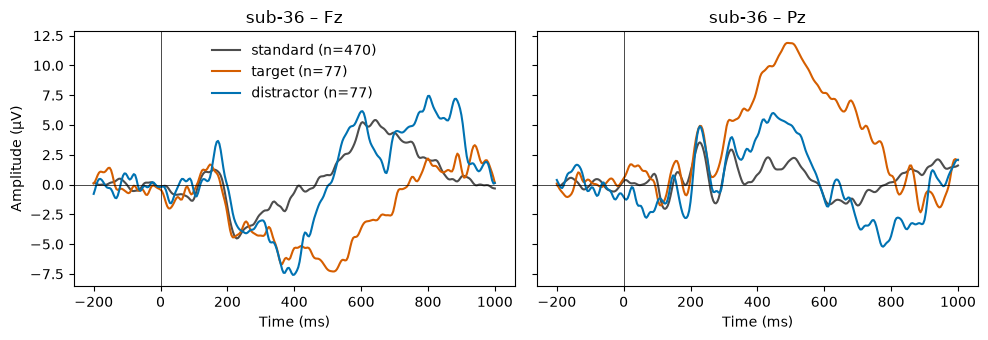

    done in 122 s | dropped 5.5 %
[37/42] sub-37 processing...


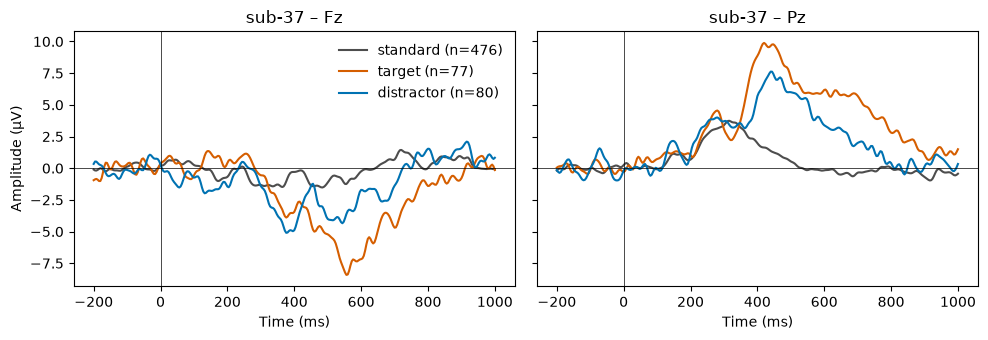

    done in 159 s | dropped 3.9 %
[38/42] sub-38 processing...


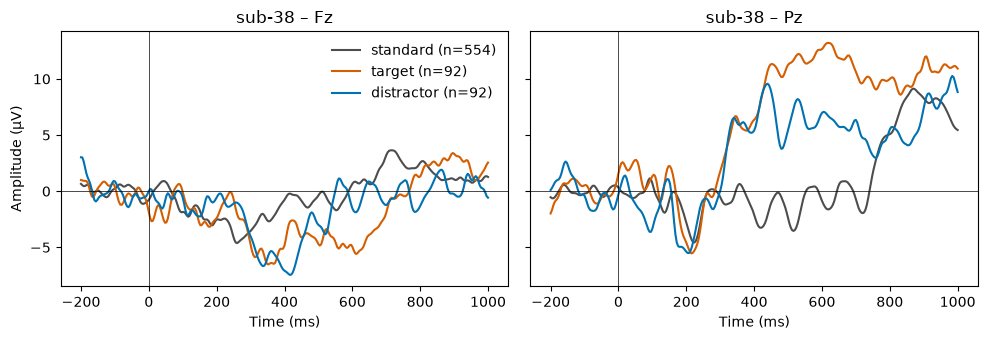

    done in 150 s | dropped 4.8 %
[39/42] sub-39 processing...


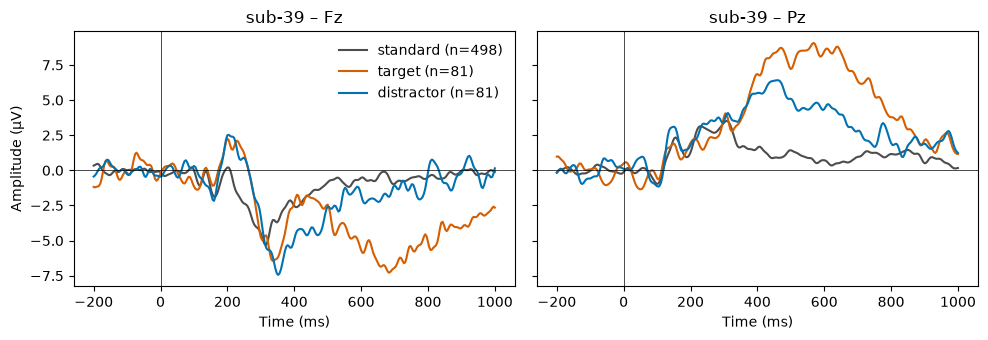

    done in 184 s | dropped 0.0 %
[40/42] sub-40 processing...


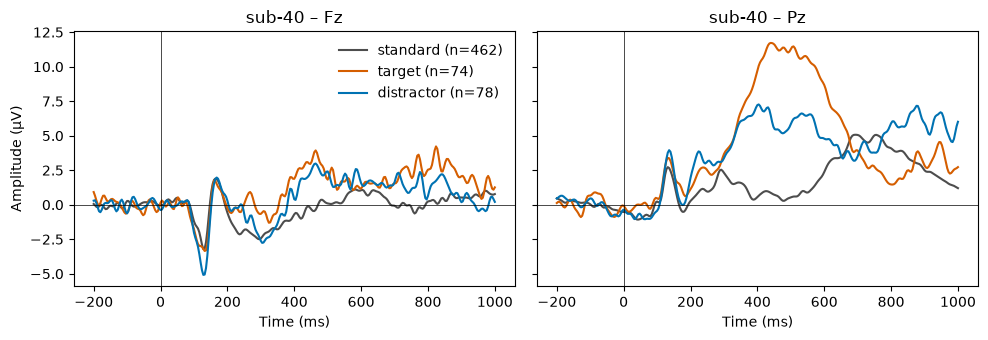

    done in 283 s | dropped 7.0 %


In [34]:
run_batch(SUBJECTS[35:40])  # sub-36 to sub-40

[41/42] sub-41 processing...


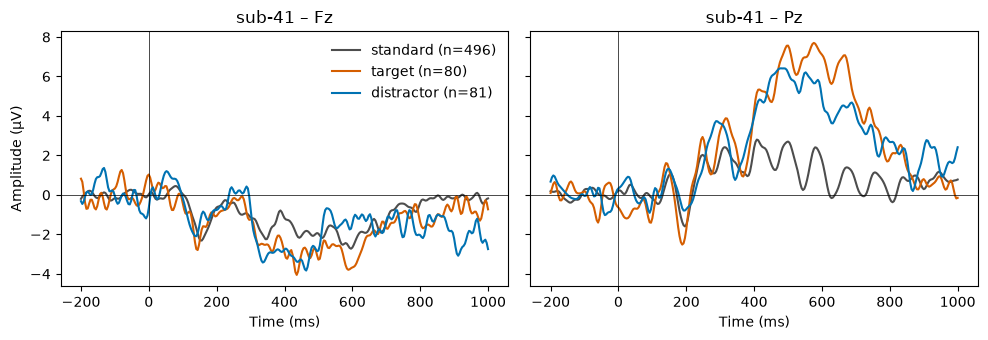

    done in 136 s | dropped 0.5 %
[42/42] sub-42 processing...


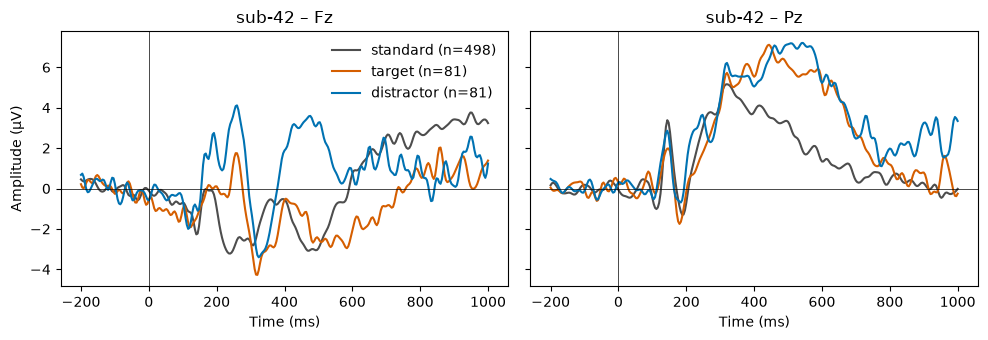

    done in 192 s | dropped 0.0 %


In [35]:
run_batch(SUBJECTS[40:45])  # sub-41 to sub-42

In [36]:
unfinished = [sub for sub in SUBJECTS if not is_done(sub)]
print("Finished", len(SUBJECTS) - len(unfinished), "of", len(SUBJECTS), "| not finished:", unfinished or "none")

Finished 42 of 42 | not finished: none


## 4. Kiểm tra chất lượng

Kỳ vọng: ở Pz, `target` cao hơn rõ so với `standard` trong khoảng 300–600 ms (`pz_p3_*`), và biên độ Fp1 giảm sau ICA.

In [41]:
qc_files = sorted((OUT_DIR / "qc").glob("sub-*.json"))
qc_table = pd.DataFrame([json.loads(p.read_text(encoding="utf-8")) for p in qc_files])
qc_table.drop(columns=["bad_channel_reasons"]).to_csv(OUT_DIR / "qc_summary.csv", index=False)
pd.set_option("display.max_columns", None)
qc_table.drop(columns=["bad_channels", "bad_channel_reasons", "ic_excluded"])

,subject,task_misunderstood,irregular_recording,high_impedance,n_recording_joins,cropped_outside_task_s,n_stimuli,n_bad_channels,n_ic_excluded,fp1_p99_before_ica_uv,fp1_p99_after_ica_uv,target_rt_ms,target_omission_pct,false_alarm_distractor_pct,false_alarm_standard_pct,n_standard_in,n_target_in,n_distractor_in,n_standard_kept,n_target_kept,n_distractor_kept,pct_trials_dropped,pz_p3_standard_uv,pz_p3_target_uv,pz_p3_distractor_uv,n_channels,n_times,runtime_s
0,sub-01,False,False,False,0,73.7,660,0,16,202.1,32.2,571.5,23.46,37.04,3.01,498,81,81,494,80,80,0.9,2.04,5.95,6.23,128,301,149
1,sub-02,True,False,False,0,58.3,660,0,16,386.4,28.3,385.2,0.00,98.77,3.21,498,81,81,491,79,80,1.5,0.90,7.09,6.53,128,301,312
2,sub-03,False,False,False,0,46.5,660,0,9,107.3,17.5,507.7,0.00,12.35,0.20,498,81,81,476,81,80,3.5,0.20,6.58,3.04,128,301,173
3,sub-04,False,False,False,0,43.6,660,0,11,199.3,24.5,552.9,2.47,6.17,0.00,498,81,81,498,81,81,0.0,1.15,4.63,3.00,128,301,251
4,sub-05,False,False,False,0,34.4,660,4,14,125.4,32.6,428.6,0.00,9.88,0.00,498,81,81,489,79,76,2.4,0.43,6.96,6.12,128,301,157
5,sub-06,False,False,False,0,43.5,660,1,15,151.2,26.0,579.6,3.70,3.70,0.20,498,81,81,483,78,78,3.2,0.61,6.61,5.47,128,301,148
6,sub-07,False,False,False,0,43.7,660,2,6,166.0,53.6,686.4,39.51,29.63,1.00,498,81,81,241,48,44,49.5,-0.07,1.82,2.34,128,301,157
7,sub-08,False,False,False,0,412.4,660,4,12,77.5,17.6,561.3,14.81,14.81,0.40,498,81,81,494,81,79,0.9,2.75,6.43,5.80,128,301,163
8,sub-09,False,False,False,0,44.4,660,0,15,155.8,18.5,592.2,12.35,8.64,0.00,498,81,81,495,78,81,0.9,-0.23,6.79,4.27,128,301,226
9,sub-10,False,False,False,0,47.3,660,2,16,170.1,95.1,545.8,17.28,39.51,1.00,498,81,81,490,81,78,1.7,0.40,7.30,4.76,128,301,372


In [42]:
# Compare behaviour with Table 5 of the paper, which excludes the same three subjects.
PAPER_TABLE_5 = {
    "target_rt_ms": (542.13, 65.50),
    "target_omission_pct": (5.60, 8.33),
    "false_alarm_distractor_pct": (9.52, 8.90),
    "false_alarm_standard_pct": (0.24, 0.46),
}
included = qc_table[~qc_table["task_misunderstood"]]
pd.DataFrame(
    [
        {
            "measure": measure,
            "ours_mean": round(included[measure].mean(), 2),
            "ours_sd": round(included[measure].std(), 2),
            "paper_mean": mean,
            "paper_sd": sd,
        }
        for measure, (mean, sd) in PAPER_TABLE_5.items()
    ]
)

,measure,ours_mean,ours_sd,paper_mean,paper_sd
0,target_rt_ms,542.14,65.50,542.13,65.50
1,target_omission_pct,5.60,8.48,5.60,8.33
2,false_alarm_distractor_pct,9.63,9.28,9.52,8.90
3,false_alarm_standard_pct,0.27,0.53,0.24,0.46


In [43]:
# Confirm every saved file has the format teammates expect.
epoch_files = sorted((OUT_DIR / "epochs").glob("sub-*-epo.fif"))
problems = []
for path in epoch_files:
    ep = mne.read_epochs(path, preload=False)
    if ep.ch_names != CHANNELS:
        problems.append(f"{path.name}: channel order")
    if len(ep.times) != 301 or ep.info["sfreq"] != 250:
        problems.append(f"{path.name}: time axis")
    if ep.metadata is None:
        problems.append(f"{path.name}: missing metadata")
print(len(epoch_files), "files checked | problems:", problems or "none")
print("Processed", len(qc_table), "of", len(SUBJECTS), "requested subjects")
print(qc_table[["pct_trials_dropped", "n_bad_channels", "n_ic_excluded", "runtime_s"]].describe().round(1))
ep.metadata.head()

42 files checked | problems: none
Processed 42 of 42 requested subjects
       pct_trials_dropped  n_bad_channels  n_ic_excluded  runtime_s
count                42.0            42.0           42.0       42.0
mean                  3.0             2.9           15.0      193.3
std                   7.8             3.4            4.7       73.4
min                   0.0             0.0            6.0      126.0
25%                   0.5             0.0           12.2      147.2
50%                   0.9             2.0           15.0      160.0
75%                   2.3             4.0           17.8      224.5
max                  49.5            14.0           25.0      465.0


,subject,trial,condition,responded,rt_ms,correct
0,sub-42,0,standard,False,NaN,True
1,sub-42,1,target,True,536.0,True
2,sub-42,2,standard,False,NaN,True
3,sub-42,3,standard,False,NaN,True
4,sub-42,4,standard,False,NaN,True


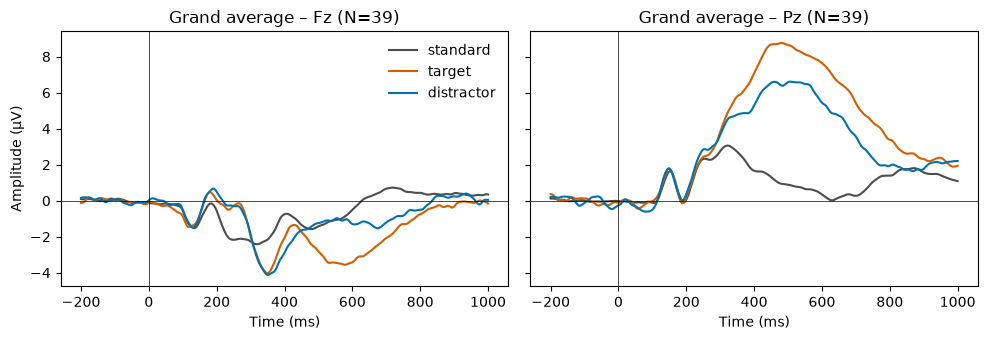

In [ ]:
# Grand average with correct trials only, as in Figure 5 of the paper.
colours = {"standard": "#4d4d4d", "target": "#d55e00", "distractor": "#0072b2"}
excluded = set(qc_table.loc[qc_table["task_misunderstood"], "subject"])
per_condition = {name: [] for name in EVENT_ID}
for path in epoch_files:
    if path.name[:6] in excluded:
        continue
    ep = mne.read_epochs(path, preload=False)
    ep = ep[ep.metadata["correct"].values]
    for name in EVENT_ID:
        per_condition[name].append(ep[name].average(picks=["Fz", "Pz"]).data * 1e6)
times = ep.times * 1000

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for i, (ax, channel) in enumerate(zip(axes, ("Fz", "Pz"))):
    for name, colour in colours.items():
        ax.plot(times, np.mean(per_condition[name], axis=0)[i], color=colour, label=name)
    ax.axvline(0, color="k", lw=0.5)
    ax.axhline(0, color="k", lw=0.5)
    ax.set(title=f"Grand average – {channel} (N={len(per_condition['target'])})", xlabel="Time (ms)")
axes[0].set_ylabel("Amplitude (µV)")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "grand_average.png", dpi=150)
plt.show()

## 5. Lưu ý

### Tải dữ liệu

Dữ liệu epoch nặng khoảng 3,6 GB nên không nằm trong lịch sử commit. Mình đưa nó lên mục **Releases** của repo, tag `data-v1`:

https://github.com/amebett1/EEG/releases/tag/data-v1

Release gồm 4 file zip:

| File | Gồm | Dung lượng |
|---|---|---|
| `epochs_v1_part1of4_sub-01_to_sub-11.zip` | sub-01 đến sub-11 | 0,91 GB |
| `epochs_v1_part2of4_sub-12_to_sub-22.zip` | sub-12 đến sub-22 | 0,94 GB |
| `epochs_v1_part3of4_sub-23_to_sub-32.zip` | sub-23 đến sub-32 | 0,88 GB |
| `epochs_v1_part4of4_sub-33_to_sub-42.zip` | sub-33 đến sub-42 | 0,88 GB |

Còn `qc_summary.csv`, `qc/` và `figures/` thì đã nằm sẵn trong repo, cứ `git clone` hoặc `git pull` là có, không cần tải riêng.

**Bước 1: tải 4 file zip.** Chọn một trong hai cách:

- Dùng trình duyệt: mở link ở trên, bấm vào từng file trong mục *Assets* để tải. Sau đó chép cả 4 file vào thư mục `derivatives/release/` trong project (chưa có thư mục thì tạo mới).
- Dùng lệnh: cài GitHub CLI một lần (`winget install GitHub.cli`, rồi `gh auth login`), mở terminal ở thư mục project và chạy:

```powershell
gh release download data-v1 --repo amebett1/EEG --dir derivatives/release
```

**Bước 2: giải nén vào `derivatives/v1/`.** Mở PowerShell ở thư mục project:

```powershell
Get-ChildItem derivatives/release/*.zip | ForEach-Object { Expand-Archive $_.FullName -DestinationPath derivatives/v1 -Force }
(Get-ChildItem derivatives/v1/epochs/*.fif).Count      # phải ra 42
```

Trên Mac hoặc Linux thì dùng: `for f in derivatives/release/*.zip; do unzip -o "$f" -d derivatives/v1; done`

Giải nén xong, thư mục sẽ trông như sau:

```
derivatives/
├── release/              # 4 file zip vừa tải, giải nén xong xóa đi cũng được
└── v1/
    ├── epochs/           
    sub-XX_task-oddball_v1-epo.fif
    ├── qc/               
    ├── figures/          
    └── qc_summary.csv    
```

Cả thư mục `derivatives/` đã nằm trong `.gitignore` (trừ mấy file QC nhỏ), nên các bạn không lo lỡ commit dữ liệu lớn lên repo.

### Trong mỗi file có gì

Mỗi file là một đối tượng `Epochs` của MNE. Một epoch ứng với một lần hiện kích thích, cắt từ 200 ms trước đến 1000 ms sau lúc kích thích xuất hiện.

- 128 kênh EEG, thứ tự kênh giống nhau ở cả 42 người nên ghép nhiều người lại được luôn. Vị trí điện cực có sẵn, vẽ topomap không cần cài thêm gì.
- Tần số lấy mẫu 250 Hz, nên mỗi epoch dài 301 mẫu.
- Đã lọc 0,5–40 Hz, đổi sang average reference, loại nhiễu mắt, tim và cơ bằng ICA, trừ baseline (−200 đến 0 ms), và bỏ những epoch có biên độ đỉnh-đỉnh trên 150 µV.
- Đơn vị là volt (MNE mặc định). Nhân `1e6` để ra µV.

Mỗi epoch đi kèm một dòng metadata:

| Cột | Ý nghĩa |
|---|---|
| `subject` | mã người, ví dụ `sub-01` |
| `trial` | thứ tự của kích thích trong buổi đo (bắt đầu từ 0) |
| `condition` | `standard`, `target` hoặc `distractor` |
| `responded` | sau kích thích này người đó có bấm nút không |
| `rt_ms` | thời gian phản ứng tính bằng ms, để trống nếu không bấm |
| `correct` | trả lời đúng hay sai: với target là bấm nút trong khoảng 100–1400 ms, với standard và distractor là không bấm |


### Một số điều cần lưu ý

1. **Chia train/test theo người**, ví dụ dùng `GroupKFold` với `groups` ở trên. Một người không được có epoch nằm ở cả tập train và tập test.
2. **Lệch lớp.** Trong các trial đúng, target chỉ chiếm khoảng 13,5% (kế hoạch ghi 10% nhưng thực tế cao hơn chút). Mô hình đoán tất cả là standard đã đạt khoảng 86% accuracy, nên hãy báo cáo balanced accuracy hoặc AUC và dùng `class_weight="balanced"` hay cách tương tự.
3. **Dữ liệu chưa chuẩn hóa.** Nếu cần z-score thì chỉ fit trên tập train của từng fold (cho `StandardScaler` vào `Pipeline`), nếu không sẽ bị rò rỉ dữ liệu.
4. **Bấm nút.** Với target, người tham gia bấm nút khoảng 540 ms sau kích thích, còn standard thì không bấm. Vì vậy mô hình có thể học cả tín hiệu vận động chứ không riêng P300. Muốn kiểm tra, chạy thêm distractor và standard: cả hai đều không bấm nút. Lần mình thử, AUC chỉ giảm từ 0,95 xuống 0,90, tức P300 vẫn là tín hiệu chính.
5. **Chớp mắt.** Nhiều người hay chớp mắt ngay sau khi bấm nút, nên nhiễu mắt cũng bám theo target. ICA đã loại phần lớn. Ở sub-13, 14 và 36, ICLabel chấm IC chớp mắt dưới ngưỡng 0,8, nên mình loại các IC này bằng tay (`EXTRA_IC_EXCLUDE`). Muốn xem mức nhiễu mắt còn lại của từng người thì xem cột `fp1_p99_after_ica_uv`.
